In [27]:
import torch

import torch.utils.data

import pandas as pd
import seaborn as sns
import scanpy as sc
import squidpy as sq

from pathlib import Path

from gctsvg import visualization
from gctsvg.preprocessing import common, singlecell, st, kidneycancer
from gctsvg.model.classifier import ClassifierDriver
from gctsvg.model.decomposer import DecomposerDriver

import matplotlib.pyplot as plt

In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
patient_id='PD47171'

In [3]:
# read ST data
adata_st = sc.read(data_dir / 'visium_merge_inter_upload.h5ad')
adata_st.var_names_make_unique()

# read scRNA data
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')
adata_sc.var_names_make_unique()

In [4]:
# Extract patient data
adata_st = kidneycancer.extract_st_patient_data(adata_st, patient_id)
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)

# extract cell type information
cell_types, n_classes = singlecell.get_cell_types(adata_sc)

In [5]:
# Format data to use ENSEMBL gene id as index
# necessary to align indexes of st and sc datasets
adata_sc = common.use_ensembl_gene_ids(adata_sc, 'name')

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [6]:
adata_sc.obs['broad_type'].values.categories.to_list()

['B-cell',
 'EC',
 'Epi_non-PT',
 'Epi_PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

In [7]:
# preprocess st and sc data
common.preprocess(adata_st)
common.preprocess(adata_sc)

In [8]:
adata_sc.obs

,orig.ident,nCount_RNA,nFeature_RNA,patient,percent.mt,summaryDescription,annotation,region,broad_type
5739STDY9266968_AACTGGTGTCTCCACT-1,5739STDY9266968,3598.0,1206,PD47171,7.254030,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_AGGGAGTGTCCGCTGA-1,5739STDY9266968,3447.0,1298,PD47171,5.686104,Tumour,Activated_B-RHOB,a,B-cell
5739STDY9266968_CATCGGGGTAAGGATT-1,5739STDY9266968,4602.0,601,PD47171,1.564537,Tumour,Plasma-IgA,a,Plasma
5739STDY9266968_CCACCTACAGCCTGTG-1,5739STDY9266968,3830.0,1854,PD47171,4.699739,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_CCACTACGTAGCGCAA-1,5739STDY9266968,3633.0,1427,PD47171,4.266446,Tumour,Activated_B-AREG,a,B-cell
...,...,...,...,...,...,...,...,...,...
5739STDY9266973_TTGTAGGTCCGCGTTT-1,5739STDY9266973,3627.0,1431,PD47171,11.524676,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTATGCGTGTGACCC-1,5739STDY9266973,3598.0,1235,PD47171,15.953307,Tumour-normal,Stress,g,RCC
5739STDY9266973_TTTGGTTAGCGACGTA-1,5739STDY9266973,3809.0,1519,PD47171,10.028879,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTGTCATCTATCCTA-1,5739STDY9266973,3901.0,1537,PD47171,5.229428,Tumour-normal,EMT,g,RCC


In [9]:
adata_st.var

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499411,mean_counts-6800STDY12499411,log1p_mean_counts-6800STDY12499411,pct_dropout_by_counts-6800STDY12499411,total_counts-6800STDY12499411,log1p_total_counts-6800STDY12499411,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std
ENSEMBL,,,,,,,,,,,,,,,,,
ENSG00000243485,Gene Expression,GRCh38,MIR1302-2HG,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000237613,Gene Expression,GRCh38,FAM138A,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000186092,Gene Expression,GRCh38,OR4F5,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000238009,Gene Expression,GRCh38,AL627309.1,False,6,0.002930,0.002925,99.707031,6.0,1.945910,False,NaN,0.002930,0.002923,0.961346,0.000191,0.003776
ENSG00000239945,Gene Expression,GRCh38,AL627309.3,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000277836,Gene Expression,GRCh38,AC141272.1,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000278633,Gene Expression,GRCh38,AC023491.2,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000276017,Gene Expression,GRCh38,AC007325.1,False,1,0.000488,0.000488,99.951172,1.0,0.693147,False,NaN,0.000488,0.000488,0.999727,0.000051,0.002288


In [10]:
# print(adata_st.var.index[adata_st.var.index.duplicated()])
print(adata_st.var[adata_st.var.index.duplicated(keep=False)])

Empty DataFrame
Columns: [feature_types, genome, SYMBOL, mt, n_cells_by_counts-6800STDY12499411, mean_counts-6800STDY12499411, log1p_mean_counts-6800STDY12499411, pct_dropout_by_counts-6800STDY12499411, total_counts-6800STDY12499411, log1p_total_counts-6800STDY12499411, highly_variable, highly_variable_rank, means, variances, variances_norm, mean, std]
Index: []


In [11]:
st_hvg = adata_st.var['highly_variable'].index
sc_hvg = adata_sc.var['highly_variable'].index

In [12]:
st_hvg

Index(['ENSG00000243485', 'ENSG00000237613', 'ENSG00000186092',
       'ENSG00000238009', 'ENSG00000239945', 'ENSG00000239906',
       'ENSG00000241860', 'ENSG00000241599', 'ENSG00000286448',
       'ENSG00000236601',
       ...
       'ENSG00000274175', 'ENSG00000275869', 'ENSG00000273554',
       'ENSG00000278782', 'ENSG00000277761', 'ENSG00000277836',
       'ENSG00000278633', 'ENSG00000276017', 'ENSG00000278817',
       'ENSG00000277196'],
      dtype='object', name='ENSEMBL', length=36601)

In [13]:
sc_hvg

Index(['ENSG00000225880', 'ENSG00000230368', 'ENSG00000188976',
       'ENSG00000187961', 'ENSG00000187583', 'ENSG00000187642',
       'ENSG00000188290', 'ENSG00000187608', 'ENSG00000188157',
       'ENSG00000131591',
       ...
       'ENSG00000242550', 'ENSG00000237914', 'ENSG00000185052',
       'ENSG00000124102', 'ENSG00000235590', 'ENSG00000101188',
       'ENSG00000115266', 'ENSG00000228817', 'ENSG00000231106',
       'ENSG00000160202'],
      dtype='object', name='ENSEMBL', length=18356)

In [14]:
geneset = st_hvg.intersection(sc_hvg)
geneset

Index(['ENSG00000225880', 'ENSG00000230368', 'ENSG00000187634',
       'ENSG00000188976', 'ENSG00000187961', 'ENSG00000187583',
       'ENSG00000187642', 'ENSG00000188290', 'ENSG00000187608',
       'ENSG00000188157',
       ...
       'ENSG00000198712', 'ENSG00000228253', 'ENSG00000198899',
       'ENSG00000198938', 'ENSG00000198840', 'ENSG00000212907',
       'ENSG00000198886', 'ENSG00000198786', 'ENSG00000198695',
       'ENSG00000198727'],
      dtype='object', name='ENSEMBL', length=15942)

In [15]:
# get feature matrices from st and sc data
geneset = common.get_common_geneset(adata_st, adata_sc)
adata_st = adata_st[:, geneset]
adata_sc = adata_sc[:, geneset]

Number of overlap genes: 896


In [16]:
adata_sc.obs

,orig.ident,nCount_RNA,nFeature_RNA,patient,percent.mt,summaryDescription,annotation,region,broad_type
5739STDY9266968_AACTGGTGTCTCCACT-1,5739STDY9266968,3598.0,1206,PD47171,7.254030,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_AGGGAGTGTCCGCTGA-1,5739STDY9266968,3447.0,1298,PD47171,5.686104,Tumour,Activated_B-RHOB,a,B-cell
5739STDY9266968_CATCGGGGTAAGGATT-1,5739STDY9266968,4602.0,601,PD47171,1.564537,Tumour,Plasma-IgA,a,Plasma
5739STDY9266968_CCACCTACAGCCTGTG-1,5739STDY9266968,3830.0,1854,PD47171,4.699739,Tumour,Naïve_B.1,a,B-cell
5739STDY9266968_CCACTACGTAGCGCAA-1,5739STDY9266968,3633.0,1427,PD47171,4.266446,Tumour,Activated_B-AREG,a,B-cell
...,...,...,...,...,...,...,...,...,...
5739STDY9266973_TTGTAGGTCCGCGTTT-1,5739STDY9266973,3627.0,1431,PD47171,11.524676,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTATGCGTGTGACCC-1,5739STDY9266973,3598.0,1235,PD47171,15.953307,Tumour-normal,Stress,g,RCC
5739STDY9266973_TTTGGTTAGCGACGTA-1,5739STDY9266973,3809.0,1519,PD47171,10.028879,Tumour-normal,PT,g,RCC
5739STDY9266973_TTTGTCATCTATCCTA-1,5739STDY9266973,3901.0,1537,PD47171,5.229428,Tumour-normal,EMT,g,RCC


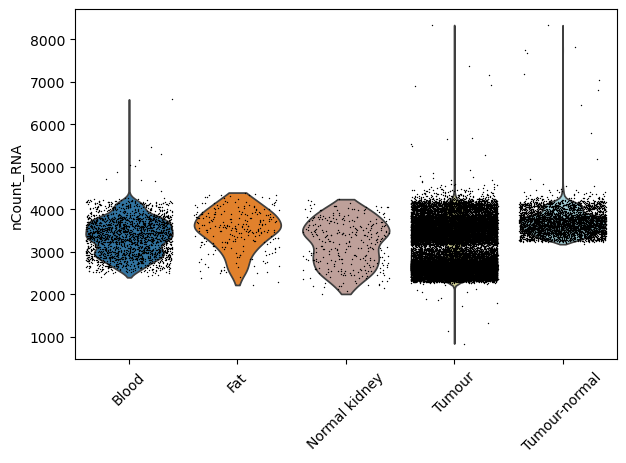

In [26]:
sc.pl.violin(adata_sc, 'nCount_RNA', groupby='summaryDescription', jitter=0.4, rotation=45)

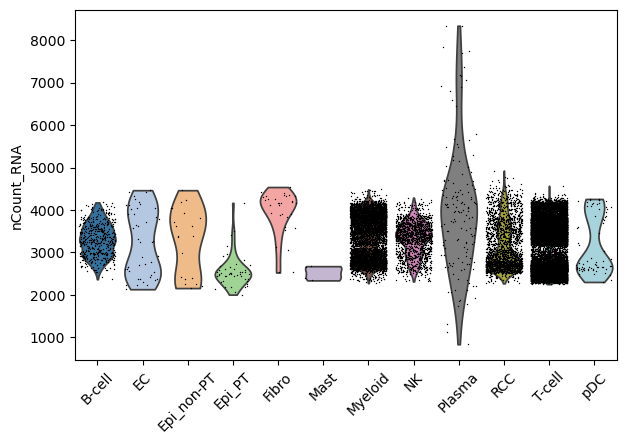

In [24]:
sc.pl.violin(adata_sc, 'nCount_RNA', groupby='broad_type', jitter=0.4, rotation=45)
# plt.show()

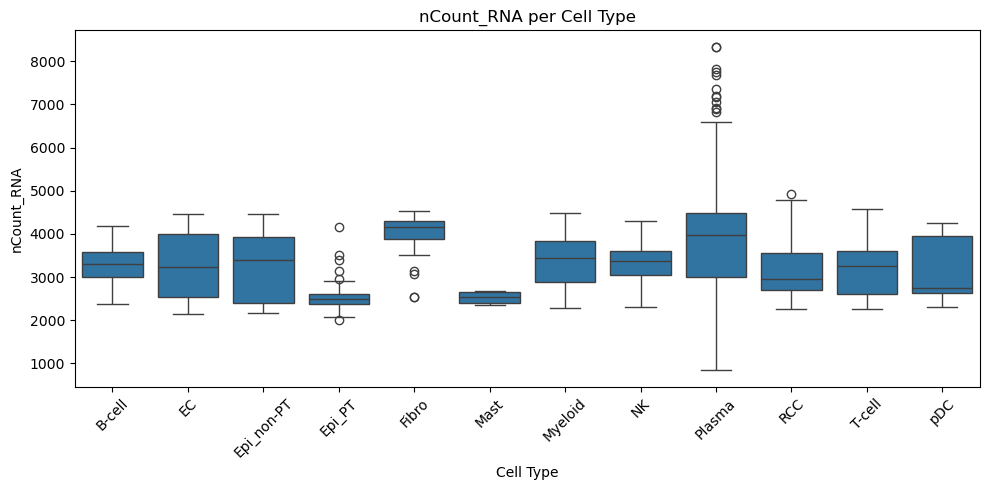

In [28]:
# Plot boxplot
plt.figure(figsize=(10, 5))
sns.boxplot(x='broad_type', y='nCount_RNA', data=adata_sc.obs)
plt.xlabel('Cell Type')
plt.ylabel('nCount_RNA')
plt.title('nCount_RNA per Cell Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

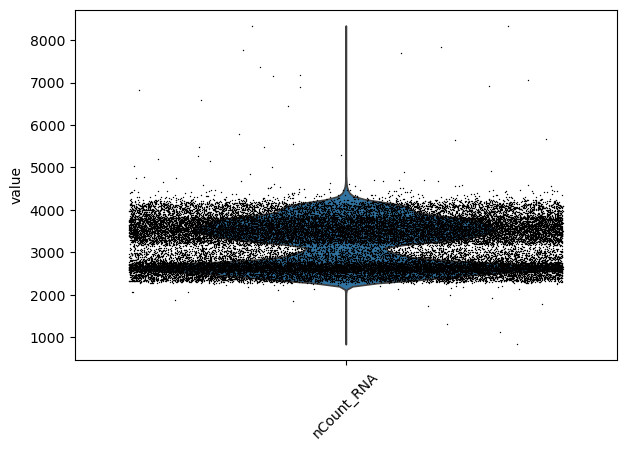

In [39]:
sc.pl.violin(adata_sc, 'nCount_RNA', jitter=0.4, rotation=45)

In [40]:
30/2000

0.015